### Імпорт бібліотек та персональні параметри

In [5]:
import os, re, time, hashlib, unicodedata, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image, ImageDraw, ImageFont
from rapidfuzz.distance import Levenshtein
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")
os.environ["PADDLE_PDX_ENABLE_MKLDNN_BYDEFAULT"] = "False"

STUDENT = "Тацюк А. В."
VARIANT = 20
STUDENT_ID = 457
SEED = 1000 * VARIANT + STUDENT_ID
rng = np.random.default_rng(SEED)

FONTS = [
    "C:/Windows/Fonts/verdana.ttf",   
    "C:/Windows/Fonts/georgia.ttf",    
    "C:/Windows/Fonts/arial.ttf",
    "C:/Windows/Fonts/times.ttf",
]

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

def stamp(ax, title):
    """Заголовок графіка з персональним підписом студента."""
    ax.set_title(f"{title}\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)

print("SEED =", SEED)

SEED = 20457


### Завантаження фото з архіву

In [6]:
import shutil
import pillow_heif
from PIL import ExifTags
pillow_heif.register_heif_opener()

SRC = "my_photos"
OUT = "my_photos_conv"
os.makedirs(OUT, exist_ok=True)

for f in sorted(os.listdir(SRC)):
    name, ext = os.path.splitext(f)
    p = os.path.join(SRC, f)
    if ext.lower() in (".heic", ".heif"):
        im = Image.open(p)
        im.save(f"{OUT}/{name}.jpg", "JPEG", quality=95,
                exif=im.info.get("exif", b""))
    elif ext.lower() in (".jpg", ".txt"):
        shutil.copy(p, OUT)

def exif_info(path):
    exif = Image.open(path).getexif()
    tags = {ExifTags.TAGS.get(k, k): v for k, v in exif.items()}
    return tags.get("DateTime"), tags.get("Model")

jpgs = sorted(f for f in os.listdir(OUT) if f.lower().endswith(".jpg"))
print("Фото:", len(jpgs), "| без транскрипції:",
      [f for f in jpgs if not os.path.exists(f"{OUT}/{f[:-4]}.txt")])
for f in jpgs:
    print(f, exif_info(f"{OUT}/{f}"))

Фото: 8 | без транскрипції: []
lic_1.jpg ('2026:10:24 23:06:52', 'iPhone 17')
lic_2.jpg ('2026:10:24 23:05:45', 'iPhone 17')
lic_3.jpg ('2026:10:24 23:08:22', 'iPhone 17')
lic_4.jpg ('2026:10:24 23:05:06', 'iPhone 17')
lic_5.jpg ('2026:10:24 23:04:54', 'iPhone 17')
text_1.jpg ('2026:10:24 23:03:10', 'iPhone 17')
text_2.jpg ('2026:10:24 23:03:22', 'iPhone 17')
text_3.jpg ('2026:10:24 23:01:53', 'iPhone 17')


### Корпус тексту для синтетичного набору

In [7]:
with open("zakhar_berkut.txt", encoding="utf-8") as f:
    raw = re.sub(r"\s+", " ", f.read())

sentences = re.split(r"(?<=[.!?…])\s+", raw)
corpus = [s.strip() for s in sentences if 20 <= len(s.strip()) <= 70]
print("Речень довжиною 20–70 символів:", len(corpus))

with open("corpus.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(corpus))
print(corpus[:5])

Речень довжиною 20–70 символів: 55
['Сумно і непривітно тепер в нашій Тухольщині!', 'Але все інше як же змінилося!', 'І ліси, і села, і люди!', 'Але найбільше змінилися люди.', 'Не так тут колись було!']


### Синтетичний набір

Речень у корпусі: 55
Записів: 240 | SHA-256 еталону: 1173153db672c88c


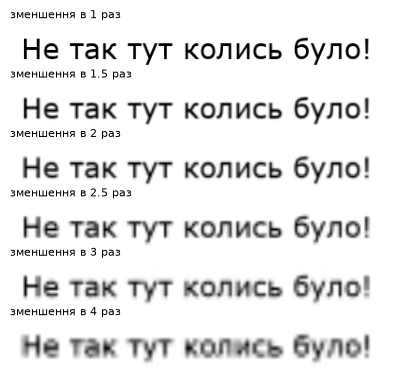

In [8]:
with open("corpus.txt", encoding="utf-8") as f:
    corpus = [s.strip() for s in f if 20 <= len(s.strip()) <= 70]
print("Речень у корпусі:", len(corpus))

lines = [str(s) for s in rng.choice(corpus, size=40, replace=False)]

def render_line(text, font_path, size=32, pad=12):
    font = ImageFont.truetype(font_path, size)
    l, t, r, b = font.getbbox(text)
    img = Image.new("L", (r - l + 2 * pad, b - t + 2 * pad), 255)
    ImageDraw.Draw(img).text((pad - l, pad - t), text, font=font, fill=0)
    return np.array(img)

def degrade(img, kind, level, rng):
    out = img.astype(np.float32)
    if kind == "scale" and level > 1:      # level: у скільки разів зменшити
        h, w = out.shape
        small = cv2.resize(out, (int(w / level), int(h / level)),
                           interpolation=cv2.INTER_AREA)
        out = cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)
    return np.clip(out, 0, 255).astype(np.uint8)

FACTOR, LEVELS = "scale", [1, 1.5, 2, 2.5, 3, 4]
FONTS_OK = [f for f in FONTS if os.path.exists(f)]

records = []
for i, text in enumerate(lines):
    font = FONTS_OK[i % len(FONTS_OK)]
    clean = render_line(text, font, size=int(rng.integers(22, 36)))
    for lvl in LEVELS:
        path = f"data/{i:03d}_{FACTOR}_{lvl}.png"
        cv2.imwrite(path, degrade(clean, FACTOR, lvl, rng))
        records.append({"id": i, "level": lvl, "path": path, "gt": text,
                        "font": os.path.basename(font)})

ds = pd.DataFrame(records)
ds.to_csv("data/ground_truth.csv", index=False)
with open("data/ground_truth.csv", "rb") as f:
    sha = hashlib.sha256(f.read()).hexdigest()[:16]
print("Записів:", len(ds), "| SHA-256 еталону:", sha)

fig, axes = plt.subplots(len(LEVELS), 1, figsize=(7, 0.75 * len(LEVELS)))
for ax, lvl in zip(axes, LEVELS):
    img = cv2.imread(f"data/000_{FACTOR}_{lvl}.png", cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap="gray")
    ax.set_title(f"зменшення в {lvl} раз", fontsize=8, loc="left")
    ax.axis("off")
fig.savefig("figures/fig0_samples.png", dpi=150, bbox_inches="tight")

### Завантаження SVHN

In [9]:
from datasets import load_dataset, get_dataset_config_names

print(get_dataset_config_names("ufldl-stanford/svhn"))

['cropped_digits', 'full_numbers']


In [10]:
stream = load_dataset("ufldl-stanford/svhn", "full_numbers", split="test", streaming=True)
first = list(stream.take(3))
print(first[0].keys())
print(first[0])

dict_keys(['image', 'digits'])
{'image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=43x19 at 0x2A3E096A8A0>, 'digits': {'bbox': [[17, 2, 6, 15], [23, 4, 5, 15]], 'label': [3, 1]}}


In [11]:
import json
from collections import Counter
from datasets import load_dataset

N = 120
samples = list(load_dataset("ufldl-stanford/svhn", "full_numbers",
                            split="test", streaming=True).take(N))

def svhn_gt(digits):
    """Еталон: мітки цифр, відсортовані за координатою left."""
    order = sorted(range(len(digits["label"])), key=lambda k: digits["bbox"][k][0])
    return "".join(str(digits["label"][k] % 10) for k in order)

os.makedirs("svhn", exist_ok=True)
svhn_rows = []
for idx, s in enumerate(samples):
    path = f"svhn/{idx:03d}.png"
    s["image"].convert("RGB").save(path)
    svhn_rows.append({"idx": idx, "path": path, "gt": svhn_gt(s["digits"]),
                      "w": s["image"].width, "h": s["image"].height})

svhn = pd.DataFrame(svhn_rows)
svhn.to_csv("svhn/ground_truth.csv", index=False)
with open("svhn/sample_ids.json", "w") as f:
    json.dump(svhn["idx"].tolist(), f)

all_labels = Counter(l for s in samples for l in s["digits"]["label"])
print("Мітки в зразках:", sorted(all_labels.items()))
print("Довжина номера:", svhn["gt"].str.len().value_counts().sort_index().to_dict())
print("Розміри зображень: ширина", svhn.w.min(), "-", svhn.w.max(),
      "| висота", svhn.h.min(), "-", svhn.h.max())
print(svhn.head())

Мітки в зразках: [(0, 15), (1, 41), (2, 35), (3, 30), (4, 25), (5, 20), (6, 16), (7, 14), (8, 14), (9, 23)]
Довжина номера: {1: 21, 2: 85, 3: 14}
Розміри зображень: ширина 31 - 1083 | висота 14 - 442
   idx          path   gt    w   h
0    0  svhn/000.png   31   43  19
1    1  svhn/001.png    3  133  60
2    2  svhn/002.png    4  239  96
3    3  svhn/003.png  649  102  40
4    4  svhn/004.png   10   72  25


1. H1 (стійкість до зниження роздільності). На синтетиці при k = 1 EasyOCR матиме CER ≤ 5 %, PaddleOCR ≤ 8 %. CER EasyOCR вперше перевищить 10 % при k = 2,5, PaddleOCR — при k = 2. Бо при шрифті 22–35 px висота малих літер 11–18 px, а при k = 2,5 вона падає до ~4–7 px, і детектори погано знаходять текст нижче ~10 px.
2. H2 (попередня обробка). На синтетиці при k = 3 (зменшення в 3 рази) збільшення ×2 + різкість (unsharp mask, власний крок) знизить CER EasyOCR щонайменше на 5 п.п. Бінаризація Оцу (після переведення в сірий) погіршить CER обох інструментів щонайменше на 3 п.п. Бо збільшення повертає літерам потрібну висоту, а різкість — контраст країв. Оцу ж змушує віднести розмиті сірі краї або до штриха, або до фону, тому дрібні штрихи рвуться чи зливаються.
3. H3 (відкритий набір). CER на SVHN буде ≥ 25 %, тобто щонайменше в 5 разів вищий, ніж на синтетиці при k = 1. Бо номери короткі (2–3 цифри): одна помилка дає 33–50 %, а невиявлений номер — 100 %.
4. H4 (лічильники). На фото лічильників CER буде ≤ 20 %. Еталон: усі 6 цифр, включно з останньою на червоному барабані. Бо цифри великі й контрастні, а фон рівний.
5. H5 (особливість варіанту). На SVHN зразки нижче 20 px матимуть CER щонайменше вдвічі вищий, ніж зразки понад 50 px, для обох інструментів. Бо на дрібних цифрах втрачаються деталі, за якими 1 відрізняється від 7, а 0 від 8.

### Встановлення й ініціалізація інструментів

In [12]:
import easyocr
from paddleocr import PaddleOCR

reader = easyocr.Reader(["uk"], gpu=False, verbose=False)

paddle = PaddleOCR(lang="uk",
                   use_doc_orientation_classify=False,
                   use_doc_unwarping=False,
                   use_textline_orientation=False)

Creating model: ('PP-OCRv5_server_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\User\.paddlex\official_models\PP-OCRv5_server_det`.
Creating model: ('eslav_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\User\.paddlex\official_models\eslav_PP-OCRv5_mobile_rec`.
